<a href="https://colab.research.google.com/github/Kristina-aut/my-pet-project/blob/main/%D0%9A%D0%BE%D1%80%D1%80%D0%B5%D0%BB%D1%8F%D1%86%D0%B8%D1%8F_%D0%BC%D0%B5%D0%B6%D0%B4%D1%83_%D1%8D%D1%82%D0%B8%D0%BC%D0%B8_%D0%BF%D0%B5%D1%80%D0%B5%D0%BC%D0%B5%D0%BD%D0%BD%D1%8B%D0%BC%D0%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
from scipy import stats
import matplotlib.pyplot as plt

In [5]:
data=pd.read_csv('/content/data.csv', encoding='1251', delimiter=',')

In [ ]:
data.head()

,Price,Value
0,10,2
1,15,25
2,20,3
3,25,35
4,3,4


In [ ]:
data.dtypes

,0
Price,int64
Value,int64


In [ ]:
data.shape

(20, 2)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Price   20 non-null     int64
 1   Value   20 non-null     int64
dtypes: int64(2)
memory usage: 452.0 bytes


In [ ]:
print(data.isnull().sum())

Price    0
Value    0
dtype: int64


In [ ]:
data.describe()

,Price,Value
count,20.000000,20.0000
mean,13.600000,14.6000
std,7.666743,11.1185
min,1.000000,2.0000
25%,9.750000,4.0000
50%,14.000000,13.0000
75%,18.250000,25.0000
max,28.000000,35.0000


In [ ]:
from scipy.stats import shapiro

In [ ]:
stat, p = shapiro(data['Price'])
print("Тест нормальности:")
print(f"Статистика теста: {stat}")
print(f"p-значение: {p}")
print()

Тест нормальности:
Статистика теста: 0.9647780161799051
p-значение: 0.6430052393704048



In [ ]:
stat, p = shapiro(data['Value'])
print("Тест нормальности:")
print(f"Статистика теста: {stat}")
print(f"p-значение: {p}")
print()

Тест нормальности:
Статистика теста: 0.87204830378355
p-значение: 0.01276684001905543



In [ ]:
numeric = ['Price', 'Value']
data[numeric].corr()

,Price,Value
Price,1.000000,0.680904
Value,0.680904,1.000000


<Axes: >

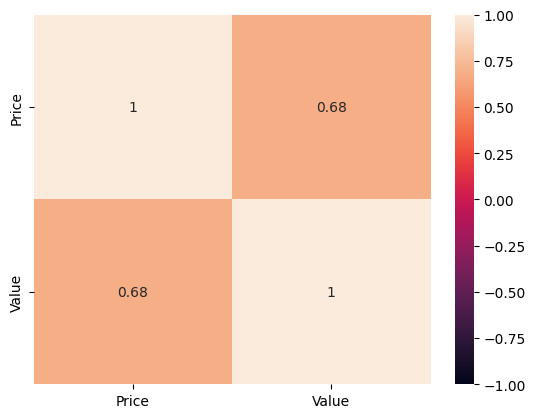

In [ ]:
sns.heatmap(data[numeric].corr(), vmin=-1,vmax=1, annot=True)

In [ ]:
import scipy as sci

In [ ]:
def Shapiro_Wilk_test(data, a_level=0.05, DecPlace=4):
    data = np.array(data)

    # Используем stats.shapiro
    result = stats.shapiro(data)
    s_calc = result.statistic  # расчетное значение статистики критерия
    a_calc = result.pvalue     # расчетный уровень значимости

    print(f"Расчетный уровень значимости: a_calc = {round(a_calc, DecPlace)}")
    print(f"Заданный уровень значимости: a_level = {round(a_level, DecPlace)}")

    if a_calc >= a_level:
        conclusion_Shw_test = (
            f"Так как a_calc = {round(a_calc, DecPlace)} >= a_level = {round(a_level, DecPlace)}, "
            f"то гипотеза о нормальности распределения по критерию Шапиро-Уилка ПРИНИМАЕТСЯ"
        )
    else:
        conclusion_Shw_test = (
            f"Так как a_calc = {round(a_calc, DecPlace)} < a_level = {round(a_level, DecPlace)}, "
            f"то гипотеза о нормальности распределения по критерию Шапиро-Уилка ОТВЕРГАЕТСЯ"
        )

    print(conclusion_Shw_test)
    return s_calc, a_calc

In [ ]:
Price=data['Price']

In [ ]:
Shapiro_Wilk_test(Price)

Расчетный уровень значимости: a_calc = 0.643
Заданный уровень значимости: a_level = 0.05
Так как a_calc = 0.643 >= a_level = 0.05, то гипотеза о нормальности распределения по критерию Шапиро-Уилка ПРИНИМАЕТСЯ


(np.float64(0.9647780161799051), np.float64(0.6430052393704048))

In [ ]:
Value=data['Value']

In [ ]:
Shapiro_Wilk_test(Value)

Расчетный уровень значимости: a_calc = 0.0128
Заданный уровень значимости: a_level = 0.05
Так как a_calc = 0.0128 < a_level = 0.05, то гипотеза о нормальности распределения по критерию Шапиро-Уилка ОТВЕРГАЕТСЯ


(np.float64(0.87204830378355), np.float64(0.01276684001905543))

Использовать классический коэффициент Пирсона нельзя.
Нарушение допущения о нормальности даже для одной из переменных делает результаты Пирсона ненадежными. Для оценки используем коэффициент Спирмена.

In [1]:
from scipy.stats import kendalltau, pearsonr, spearmanr

In [6]:
spearmanr(data.Price, data.Value)

SignificanceResult(statistic=np.float64(0.6031858454505417), pvalue=np.float64(0.004870619701001255))

Полученные результаты свидетельствуют о наличии статистически значимой, прямой, уверенной взаимосвязи между признаками (коэффициент корреляции = 0.4494, \(p = **0.0048**\), что ниже уровня 0.05).
# Таким образом, с ростом значений одной переменной закономерно увеличиваются значения другой - с ростом цены растут и объем продаж

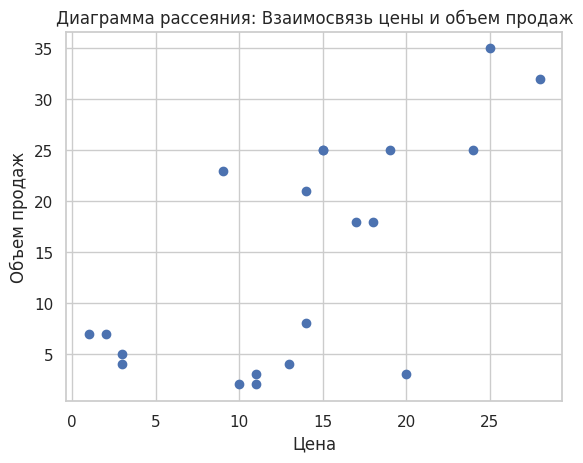

In [ ]:
plt.scatter(data['Price'], data['Value'])
plt.title('Диаграмма рассеяния: Взаимосвязь цены и объем продаж')
plt.xlabel('Цена')
plt.ylabel('Объем продаж')

plt.show()

In [ ]:
correlation = pearsonr(Price, Value)
print("Корреляция между ценой и объемом продаж:", correlation)

Корреляция между ценой и объемом продаж: PearsonRResult(statistic=np.float64(0.6809042355030791), pvalue=np.float64(0.0009503846229577792))
